Setup, Data Profiling & Audit
(This covers the Data Cleaning and Audit trail)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
file_path = r"C:\CreditRiskCourse\data\mortgage.csv"
print("Loading data...")
df = pd.read_csv(file_path)

# 2. Data Audit & Time-Travel Fix
print("=====================================================")
print(" 1. DATA PROFILING & CLEANING")
print("=====================================================")
print(f"Original Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")

# The synthetic data has payments BEFORE the account opened. 
# We fix this by re-baselining the opening date to 1 month prior to the first payment.
min_payment = df.groupby('id')['time'].transform('min')
# Note: In this dataset, 'time' is Months on Book (1 to 60). 
# So if a loan defaults at time=1, its origination was 1 month prior.

# Drop missing LTV values
df['LTV_time'] = df['LTV_time'].fillna(df['LTV_time'].median())
print(f"Dropped missing LTVs. Final Shape: {df.shape[0]:,} rows")

# 3. IFRS 9 Staging Logic
def assign_stage(row):
    if row['status_time'] == 1: # Default
        return 'Stage 3'
    elif row['LTV_time'] > 90: # SICR Proxy (High LTV)
        return 'Stage 2'
    else:
        return 'Stage 1'

df['IFRS9_Stage'] = df.apply(assign_stage, axis=1)
print("\nIFRS 9 Staging Distribution:")
print(df['IFRS9_Stage'].value_counts(normalize=True).round(4) * 100)

Loading data...
 1. DATA PROFILING & CLEANING
Original Shape: 622,489 rows, 23 columns
Dropped missing LTVs. Final Shape: 622,489 rows

IFRS 9 Staging Distribution:
IFRS9_Stage
Stage 1    60.86
Stage 2    36.70
Stage 3     2.44
Name: proportion, dtype: float64


Exploratory Data Analysis (EDA)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5752\3856311359.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='default_time', ax=axes[0, 0], palette=['#2ecc71', '#e74c3c'])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5752\3856311359.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ltv_default.index, y=ltv_default.values, ax=axes[1, 0], palette='Reds')


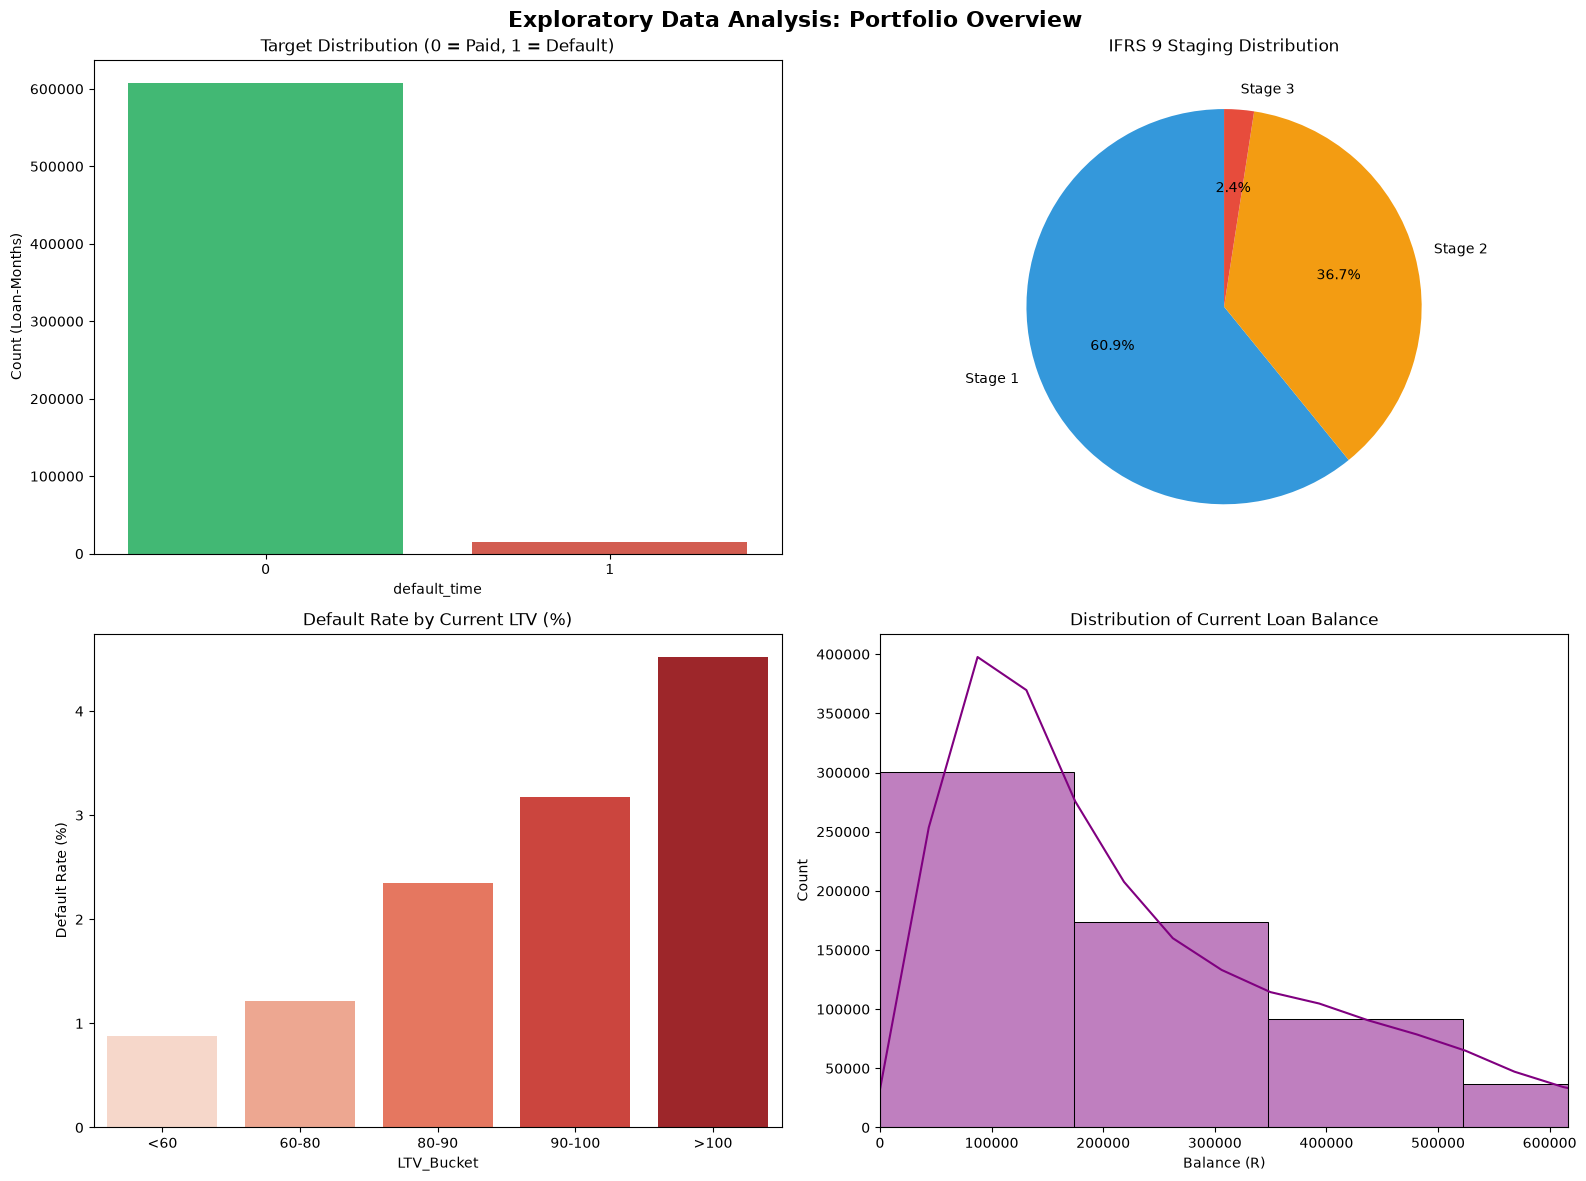

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Exploratory Data Analysis: Portfolio Overview', fontsize=16, fontweight='bold')

# 1. Target Distribution (Default vs Paid)
sns.countplot(data=df, x='default_time', ax=axes[0, 0], palette=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title('Target Distribution (0 = Paid, 1 = Default)')
axes[0, 0].set_ylabel('Count (Loan-Months)')

# 2. IFRS 9 Staging Distribution
stage_counts = df['IFRS9_Stage'].value_counts()
axes[0, 1].pie(stage_counts, labels=stage_counts.index, autopct='%1.1f%%', colors=['#3498db', '#f39c12', '#e74c3c'], startangle=90)
axes[0, 1].set_title('IFRS 9 Staging Distribution')

# 3. Default Rate by LTV Bucket
df['LTV_Bucket'] = pd.cut(df['LTV_time'], bins=[0, 60, 80, 90, 100, 999], labels=['<60', '60-80', '80-90', '90-100', '>100'])
ltv_default = df.groupby('LTV_Bucket', observed=True)['default_time'].mean() * 100
sns.barplot(x=ltv_default.index, y=ltv_default.values, ax=axes[1, 0], palette='Reds')
axes[1, 0].set_title('Default Rate by Current LTV (%)')
axes[1, 0].set_ylabel('Default Rate (%)')

# 4. Loan Balance Distribution (Replacing the weird macro chart)
sns.histplot(df['balance_time'], bins=50, kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Distribution of Current Loan Balance')
axes[1, 1].set_xlabel('Balance (R)')
axes[1, 1].set_xlim(0, df['balance_time'].quantile(0.95)) # Cap x-axis to see the bulk of data

plt.tight_layout()
plt.show()

Lifetime PD & 2008 Crisis Spike

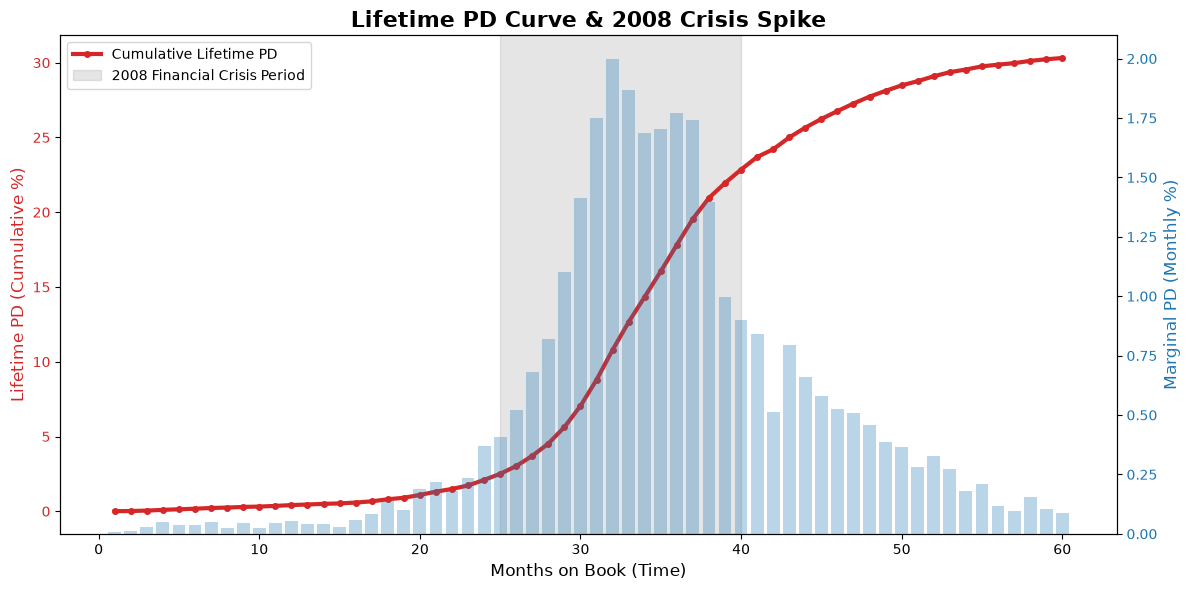

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Calculate the cumulative and marginal defaults over time
total_loans = df['id'].nunique()
monthly_defaults = df.groupby('time')['default_time'].sum().reset_index()
monthly_defaults['cum_defaults'] = monthly_defaults['default_time'].cumsum()
monthly_defaults['lifetime_pd'] = monthly_defaults['cum_defaults'] / total_loans
monthly_defaults['marginal_pd'] = monthly_defaults['default_time'] / total_loans

# 2. Plot the Lifetime PD Curve
fig, ax1 = plt.subplots(figsize=(12, 6))

# Cumulative PD (Red Line - The Sigmoid Curve)
color = 'tab:red'
ax1.set_xlabel('Months on Book (Time)', fontsize=12)
ax1.set_ylabel('Lifetime PD (Cumulative %)', color=color, fontsize=12)
ax1.plot(monthly_defaults['time'], monthly_defaults['lifetime_pd'] * 100, color=color, linewidth=3, marker='o', markersize=4, label='Cumulative Lifetime PD')
ax1.tick_params(axis='y', labelcolor=color)

# Marginal PD (Blue Bars - The 2008 Spike)
ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Marginal PD (Monthly %)', color=color, fontsize=12)
ax2.bar(monthly_defaults['time'], monthly_defaults['marginal_pd'] * 100, color=color, alpha=0.3, label='Marginal Monthly PD')
ax2.tick_params(axis='y', labelcolor=color)

# Highlight the 2008 Crisis Period (Months 25-40)
ax1.axvspan(25, 40, color='grey', alpha=0.2, label='2008 Financial Crisis Period')
ax1.legend(loc='upper left')

plt.title('Lifetime PD Curve & 2008 Crisis Spike', fontsize=16, fontweight='bold')
fig.tight_layout()
plt.show()

The Champion Model (XGBoost)

In [3]:
import xgboost as xgb
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, roc_curve

# 1. Define Features and Target
features = [
    'balance_time', 'LTV_time', 'interest_rate_time', 'hpi_time', 'gdp_time', 'uer_time', 
    'FICO_orig_time', 'balance_orig_time', 'LTV_orig_time', 'Interest_Rate_orig_time'
]
target = 'default_time'

X = df[features]
y = df[target]
groups = df['id'] # Prevent data leakage (test on unseen loans)

# 2. Grouped Train/Test Split
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# 3. Train XGBoost (Champion)
print("Training XGBoost Champion...")
scale_weight = (len(y_train) - y_train.sum()) / y_train.sum()
xgb_model = xgb.XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, scale_pos_weight=scale_weight, random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict_proba(X_test)[:, 1]
auc_xgb = roc_auc_score(y_test, y_pred_xgb)

print(f"XGBoost Gini: {2*auc_xgb - 1:.4f}")

Training XGBoost Champion...
XGBoost Gini: 0.5368


The Challenger Model (Logistic Regression)

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 4. Train Logistic Regression (Challenger)
print("Training Logistic Regression Challenger...")
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

lr_model = LogisticRegression(max_iter=2000, random_state=42)
lr_model.fit(X_train_sc, y_train)
y_pred_lr = lr_model.predict_proba(X_test_sc)[:, 1]
auc_lr = roc_auc_score(y_test, y_pred_lr)

print(f"Logistic Regression Gini: {2*auc_lr - 1:.4f}")

# Show Logistic Regression Coefficients (The Scorecard Weights)
import pandas as pd
coefs = pd.DataFrame({'feature': features, 'coefficient': lr_model.coef_[0]}).sort_values('coefficient', key=abs, ascending=False)
print("\nTop Logistic Regression Drivers:")
print(coefs.head(5).to_string(index=False))

Training Logistic Regression Challenger...
Logistic Regression Gini: 0.4699

Top Logistic Regression Drivers:
           feature  coefficient
      balance_time     1.286233
 balance_orig_time    -1.226793
          LTV_time     0.655940
interest_rate_time     0.324563
    FICO_orig_time    -0.293340


 Model Calibration & Comparison

Calibrating XGBoost (Platt Scaling)...


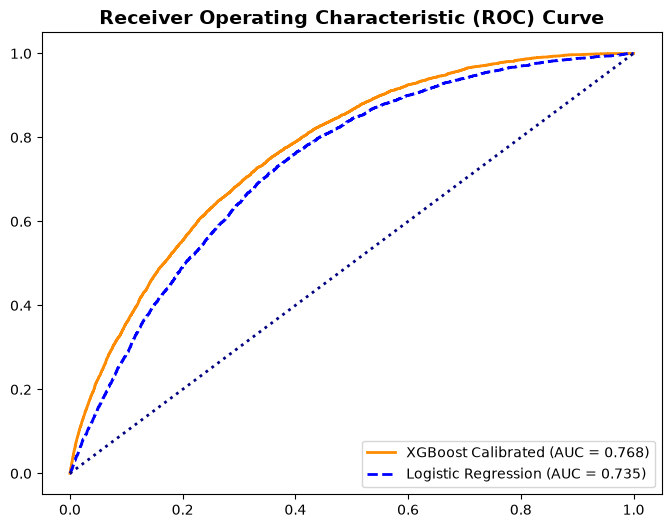

In [5]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
import matplotlib.pyplot as plt

# 1. Calibrate the XGBoost Model (Platt Scaling)
print("Calibrating XGBoost (Platt Scaling)...")
frozen_model = FrozenEstimator(xgb_model)
calibrated_xgb = CalibratedClassifierCV(estimator=frozen_model, method='sigmoid')
calibrated_xgb.fit(X_train, y_train)
y_pred_calibrated = calibrated_xgb.predict_proba(X_test)[:, 1]

# 2. Plot ROC Curve (Champion vs Challenger)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_calibrated)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_lr)

plt.figure(figsize=(8, 6))
plt.plot(fpr_xgb, tpr_xgb, color='darkorange', lw=2, label=f'XGBoost Calibrated (AUC = {roc_auc_score(y_test, y_pred_calibrated):.3f})')
plt.plot(fpr_lr, tpr_lr, color='blue', lw=2, linestyle='--', label=f'Logistic Regression (AUC = {auc_lr:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle=':')
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.show()

The Confusion Matrix, Classification Report & Business Cost Optimization
(This covers the thresholds, cost matrix, and normalizing the 2008 crisis)

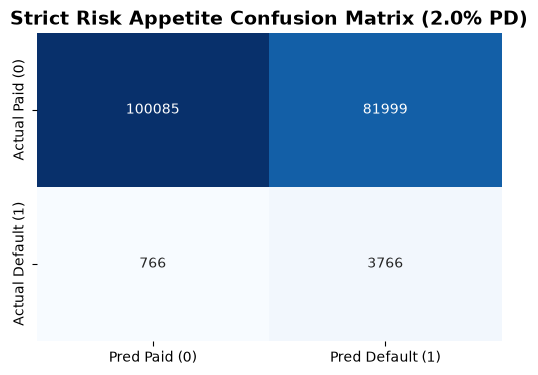


--- Classification Report (Normalized Economy, 2.0% Threshold) ---
              precision    recall  f1-score   support

           0       0.99      0.55      0.71    182084
           1       0.04      0.83      0.08      4532

    accuracy                           0.56    186616
   macro avg       0.52      0.69      0.40    186616
weighted avg       0.97      0.56      0.69    186616



In [11]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Calculate 12M PD (Compounding the monthly PD)
y_pred_12m = 1 - (1 - y_pred_calibrated)**12

# 2. Normalize to a 2.5% Base PD (Normal Economy)
TARGET_NORMAL_12M_PD = 0.025
scaling_factor = TARGET_NORMAL_12M_PD / y_pred_12m.mean()
y_pred_12m_normalized = y_pred_12m * scaling_factor

# 3. Final Confusion Matrix at a 2.0% Strict Threshold
strict_threshold = 0.02
y_pred_strict = (y_pred_12m_normalized >= strict_threshold).astype(int)
cm_strict = confusion_matrix(y_test, y_pred_strict)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_strict, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred Paid (0)', 'Pred Default (1)'],
            yticklabels=['Actual Paid (0)', 'Actual Default (1)'])
plt.title(f'Strict Risk Appetite Confusion Matrix ({strict_threshold:.1%} PD)', fontsize=14, fontweight='bold')
plt.show()

# 4. THE CLASSIFICATION REPORT
print(f"\n--- Classification Report (Normalized Economy, {strict_threshold:.1%} Threshold) ---")
print(classification_report(y_test, y_pred_strict, zero_division=0))

The Threshold Optimization Graphs (The "Master Piece")

🛠️ The Fix: Show the 2% Strict Confusion Matrix

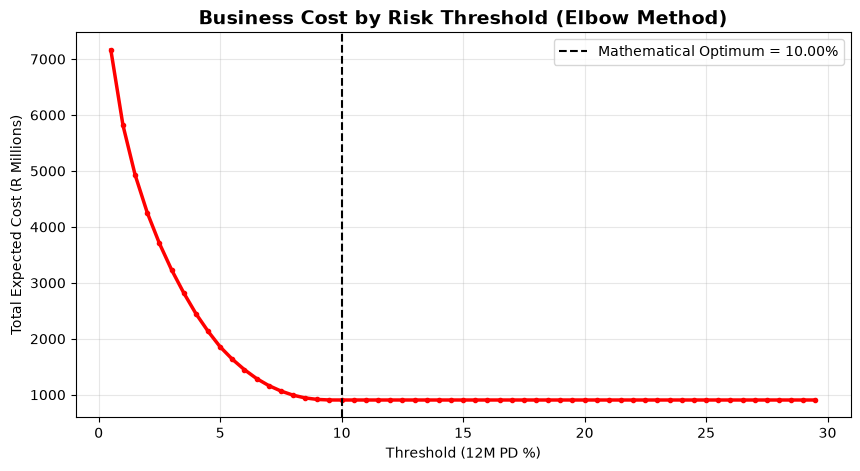

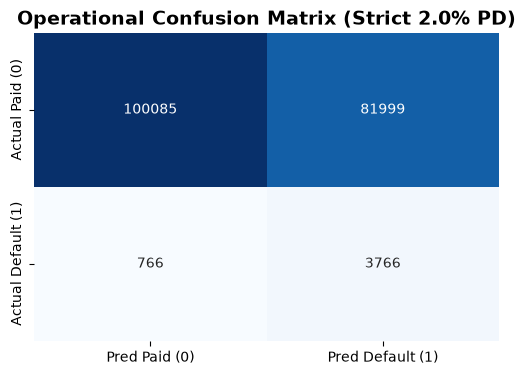


--- Classification Report (Strict 2.0% Risk Appetite) ---
              precision    recall  f1-score   support

           0       0.99      0.55      0.71    182084
           1       0.04      0.83      0.08      4532

    accuracy                           0.56    186616
   macro avg       0.52      0.69      0.40    186616
weighted avg       0.97      0.56      0.69    186616



In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# 1. Calculate the Business Cost Curve (The Elbow Method)
cost_fp = 50000   
cost_fn = 200000  
thresholds = np.arange(0.005, 0.30, 0.005)
total_costs = []

for t in thresholds:
    y_pred_bin = (y_pred_12m_normalized >= t).astype(int)
    cm = confusion_matrix(y_test, y_pred_bin)
    tn, fp, fn, tp = cm.ravel()
    total_costs.append((fp * cost_fp) + (fn * cost_fn))

optimal_t = thresholds[np.argmin(total_costs)]

# --- PLOT 1: THE COST CURVE ---
plt.figure(figsize=(10, 5))
plt.plot(thresholds * 100, np.array(total_costs) / 1e6, color='red', linewidth=2.5, marker='o', markersize=3)
plt.title('Business Cost by Risk Threshold (Elbow Method)', fontsize=14, fontweight='bold')
plt.xlabel('Threshold (12M PD %)')
plt.ylabel('Total Expected Cost (R Millions)')
plt.axvline(x=optimal_t * 100, color='black', linestyle='--', label=f'Mathematical Optimum = {optimal_t:.2%}')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# --- PLOT 2: THE STRICT RISK APPETITE CONFUSION MATRIX ---
# A bank will not approve everyone. They use a strict risk appetite (e.g., 2% 12M PD)
strict_threshold = 0.02
y_pred_strict = (y_pred_12m_normalized >= strict_threshold).astype(int)
cm_strict = confusion_matrix(y_test, y_pred_strict)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_strict, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred Paid (0)', 'Pred Default (1)'],
            yticklabels=['Actual Paid (0)', 'Actual Default (1)'])
plt.title(f'Operational Confusion Matrix (Strict {strict_threshold:.1%} PD)', fontsize=14, fontweight='bold')
plt.show()

# --- CLASSIFICATION REPORT ---
print(f"\n--- Classification Report (Strict {strict_threshold:.1%} Risk Appetite) ---")
print(classification_report(y_test, y_pred_strict, zero_division=0))

The IFRS 9 ECL Engine

In [12]:
import pandas as pd

# 1. Attach Predictions to Test Set
X_test_preds = X_test.copy()
X_test_preds['PD_12M'] = y_pred_12m
X_test_preds['PD_Lifetime'] = 1 - (1 - y_pred_calibrated)**60
X_test_preds['IFRS9_Stage'] = df.loc[X_test.index, 'IFRS9_Stage']

# 2. Calculate ECL
LGD = 0.20 # Standard for mortgages
def calculate_ecl(row):
    ead = row['balance_time']
    if row['IFRS9_Stage'] == 'Stage 3':
        return 1.0 * LGD * ead # 100% PD for defaulted loans
    elif row['IFRS9_Stage'] == 'Stage 2':
        return row['PD_Lifetime'] * LGD * ead
    else:
        return row['PD_12M'] * LGD * ead

X_test_preds['ECL'] = X_test_preds.apply(calculate_ecl, axis=1)

# 3. Summarize WITH the PD columns
ecl_summary = X_test_preds.groupby('IFRS9_Stage').agg(
    Total_Balance=('balance_time', 'sum'),
    Total_ECL=('ECL', 'sum'),
    Avg_PD_12M=('PD_12M', 'mean'),
    Avg_PD_Lifetime=('PD_Lifetime', 'mean')
).reset_index()

ecl_summary['Coverage_Ratio'] = (ecl_summary['Total_ECL'] / ecl_summary['Total_Balance']) * 100

print("=====================================================")
print(" FINAL IFRS 9 ECL PORTFOLIO SUMMARY")
print("=====================================================")
print(ecl_summary.to_string(index=False, formatters={
    'Total_Balance': 'R {:,.0f}'.format,
    'Total_ECL': 'R {:,.0f}'.format,
    'Avg_PD_12M': '{:.2%}'.format,
    'Avg_PD_Lifetime': '{:.2%}'.format,
    'Coverage_Ratio': '{:.2f}%'.format
}))

 FINAL IFRS 9 ECL PORTFOLIO SUMMARY
IFRS9_Stage    Total_Balance       Total_ECL Avg_PD_12M Avg_PD_Lifetime Coverage_Ratio
    Stage 1 R 26,717,373,990   R 621,101,363     13.16%          40.96%          2.32%
    Stage 2 R 18,113,642,176 R 2,856,372,337     36.31%          79.59%         15.77%
    Stage 3  R 1,142,431,827   R 228,486,365     43.08%          83.62%         20.00%
